In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact, Dropdown, IntSlider
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
df = pd.read_csv('Sample-Superstore.csv', encoding="latin-1")

# Basic data exploration
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

df.info()
df.describe()
df.isnull().sum()

Dataset Shape: (9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-nu

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [ ]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Display rows with missing values
df[df.isnull().any(axis=1)]

# Remove rows containing missing values (using dropna)
df = df.dropna()

print("Remaining missing values:")
print(df.isnull().sum())

# Count duplicates
print("Duplicate rows:", df.duplicated().sum())
# Remove duplicate records
df = df.drop_duplicates()

print("Duplicate rows after removal:", df.duplicated().sum())

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Number of duplicate rows: 0
Remaining missing values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64
Duplicate rows: 0
Duplicate rows after removal: 0


Handling Missing Values

After examining the dataset using df.isnull().sum(), we need to identify whether any columns contain missing values.

If a column contains only a small number of missing records (< 5% of the dataset), those rows can be removed using dropna() without significantly affecting the analysis.
If missing values occur in numerical columns and represent a meaningful attribute, imputing with the median is preferred because it is robust to outliers.
For categorical variables, the mode (most frequent category) is a suitable replacement because it preserves the distribution of categories.

The chosen method depends on the proportion and nature of missing values in each column.

In [3]:
# Handle missing values
if df.isnull().sum().sum() > 0:
    num_cols = df.select_dtypes(include=['int64', 'float64']).columns
    cat_cols = df.select_dtypes(include=['object']).columns

    for col in num_cols:
        df[col].fillna(df[col].median(), inplace=True)

    for col in cat_cols:
        df[col].fillna(df[col].mode()[0], inplace=True)

# Remove duplicates
df = df.drop_duplicates()

print("Final dataset shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
print("Remaining duplicates:", df.duplicated().sum())

Final dataset shape: (9994, 21)
Remaining missing values: 0
Remaining duplicates: 0


Using dropna() can significantly reduce the size of a dataset and potentially remove valuable data and introduce bias is missing values are concentrated in certain categories or periods. It is therefore best to use fillna() to put the me dian into numerical columns as it's less sensitive to outliers. This is very important for datasets for sales, for example.
For categorical columns, fillna() uses mode, as it is already the most frequent so it preserves the existing distribution of categories.
Duplicate records were identified using duplicated() and removed using drop_duplicates().
These steps improve data quality and ensure that subsequent exploratory data analysis and visualisations are based on accurate, non-redundant information.

In [7]:
# Convert date columns to datetime
date_columns = ['Order Date', 'Ship Date']
for col in date_columns:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col])

# Verify the conversion
print("Data types after conversion:")
print(df[date_columns].dtypes)

datetime_cols = df.select_dtypes(include=['datetime64[ns]']).columns
print("Datetime columns:")
print(datetime_cols)

Data types after conversion:
Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object
Datetime columns:
Index([], dtype='str')


The Order Date and Ship Date columns were identified as date fields and converted to datetime objects using pd.to_datetime(). Converting these columns allows for time-series analysis, including trend analysis, monthly aggregation, shipping duration calculations, and date-based filtering. Other columns were not converted because they do not represent date or time information and should remain in their original data types.

Therefore, the requirement is met only if Order Date and Ship Date are the only date-related columns in the dataset. If additional date columns exist, they would need to be added to the date_columns list and converted as well.

In [5]:
# Feature engineering
df['Profit Margin'] = (df['Profit'] / df['Sales']) * 100
df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month
df['Order Month-Year'] = df['Order Date'].dt.to_period('M')

# Display sample of new features
print("New features created:")
print(df[['Sales', 'Profit', 'Profit Margin', 'Order Year', 'Order Month']].head())

New features created:
      Sales    Profit  Profit Margin  Order Year  Order Month
0  261.9600   41.9136          16.00        2016           11
1  731.9400  219.5820          30.00        2016           11
2   14.6200    6.8714          47.00        2016            6
3  957.5775 -383.0310         -40.00        2015           10
4   22.3680    2.5164          11.25        2015           10


Feature engineering is the process of creating, modifying, or transforming variables (features) in a dataset to make them more useful for analysis or predictive modelling.

The main purpose is to extract more meaningful information from the existing data, helping you uncover patterns, improve visualisations, and increase model performance. Creating new features can reveal trends more clearly and can allow analysis broken down to monthly, quarterly or year-on-year growth. This also eventually can help with machine learning data analysis.

In [ ]:
# Prepare data for time series analysis
monthly_sales = df.groupby(['Order Month-Year', 'Category'])['Sales'].sum().reset_index()
monthly_sales['Date'] = monthly_sales['Order Month-Year'].dt.to_timestamp()

# Interactive time series plot
def plot_monthly_sales(category='All'):
    plt.figure(figsize=(12, 6))

    if category == 'All':
        # Plot total sales across all categories
        total_monthly = df.groupby('Order Month-Year')['Sales'].sum()
        plt.plot(total_monthly.index.to_timestamp(), total_monthly.values, 
                marker='o', linewidth=2, markersize=4)
        plt.title('Monthly Sales Trend - All Categories', fontsize=16, fontweight='bold')
    else:
        # Plot sales for specific category
        category_data = monthly_sales[monthly_sales['Category'] == category]
        plt.plot(category_data['Date'], category_data['Sales'], 
                marker='o', linewidth=2, markersize=4)
        plt.title(f'Monthly Sales Trend - {category}', fontsize=16, fontweight='bold')

    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Sales ($)', fontsize=12)
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Create interactive widget
categories = ['All'] + list(df['Category'].unique())
category_dropdown = Dropdown(options=categories, value='All', description='Category:')
interact(plot_monthly_sales, category=category_dropdown);



interactive(children=(Dropdown(description='Category:', options=('All', 'Furniture', 'Office Supplies', 'Techn…

There are peaks in all departments twice a year - most likely associated with the start of academic year and just prior to the Christmas break. There is always a huge slump just before year end or in January. Sales clearly go in regular cycles - but something clearly changed in 2017 as the pattern deviated from the previous years. There appears to be an overall upward trend in furniture sales over time. While sales fluctuate considerably from month to month, the highest sales figures occur in 2016 and 2017, suggesting that the Furniture category experienced growth throughout the period.

Overall Summary of Monthly Sales Trends (2014–2017)

The four charts collectively indicate that the business experienced steady growth between 2014 and 2017, with all product categories showing increasing sales over time. While monthly sales fluctuate considerably, a clear pattern of seasonal demand is evident across the entire business.

Overall Business Performance (All Categories)

The All Categories chart demonstrates the strongest overall upward trend, with monthly sales increasing from relatively modest levels in 2014 to a peak of approximately $120,000 in late 2017. Recurring spikes towards the end of each year suggest strong seasonal demand (most likely coinciding with the start of academic year and leading into the festive period), while the increasing peak values indicate sustained business growth.

Furniture

Furniture sales show a positive long-term trend but exhibit considerable month-to-month volatility. Sales often fluctuate between low and high extremes, with peak sales reaching approximately $37,000. Seasonal peaks are visible throughout the period, particularly towards year-end (leading into the festive period, i.e. when people are spending a lot more time at home), indicating that furniture purchases are strongly influenced by seasonal demand and promotional cycles.

Office Supplies

Office Supplies display consistent growth with slightly more stable sales patterns than Furniture. Monthly sales reach approximately $38,000 at their highest point, with notable peaks occurring towards the end of each year. While sales fluctuate, the category demonstrates steady performance and contributes significantly to overall revenue growth.

Technology

Technology is the strongest-performing category, generating both the highest sales volumes and the highest growth rate. Monthly sales peak at approximately $50,000 in late 2017, exceeding both Furniture and Office Supplies. Technology also exhibits clear seasonal spikes and appears to be a major driver of the company's overall sales growth.

Comparative Insights
Technology is the highest-performing category, achieving the largest sales peaks and strongest growth trajectory.
Office Supplies and Furniture exhibit similar maximum sales levels (around $37,000–$38,000), although Office Supplies appear slightly more stable.
All three categories show recurring year-end sales surges, suggesting strong seasonal demand across the business.
The substantial difference between the category-level charts and the All Categories chart indicates that overall business success is driven by contributions from all product categories rather than any single category.

Conclusion
The monthly sales analysis reveals a growing business with strong seasonal purchasing patterns. Technology is the primary growth driver, delivering the highest sales volumes and strongest upward trend. Furniture and Office Supplies also contribute significantly to revenue growth, displaying consistent seasonal peaks and increasing sales over time. The recurring end-of-year surges across all categories suggest that seasonal demand and promotional activity play a key role in overall business performance.

In [13]:
# Prepare geographic sales data
state_sales = df.groupby('State')['Sales'].sum().sort_values(ascending=True)

# Interactive geographic analysis
def plot_top_states(top_n=10):
    plt.figure(figsize=(12, max(6, top_n * 0.4)))

    # Get top N states
    top_states = state_sales.tail(top_n)

    # Create horizontal bar chart
    bars = plt.barh(range(len(top_states)), top_states.values, color='steelblue')
    plt.yticks(range(len(top_states)), top_states.index)
    plt.xlabel('Total Sales ($)', fontsize=12)
    plt.ylabel('State', fontsize=12)
    plt.title(f'Top {top_n} States by Sales Performance', fontsize=16, fontweight='bold')

    # Add value labels on bars
    for i, (state, value) in enumerate(top_states.items()):
        plt.text(value + max(top_states.values) * 0.01, i, f'${value:,.0f}', 
                va='center', fontsize=10)

    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"Total states analyzed: {len(state_sales)}")
    print(f"Top {top_n} states represent: ${top_states.sum():,.0f} in sales")

# Create interactive slider
top_n_slider = IntSlider(min=5, max=25, value=10, description='Top N States:')
interact(plot_top_states, top_n=top_n_slider);

interactive(children=(IntSlider(value=10, description='Top N States:', max=25, min=5), Output()), _dom_classes…

High performing states are California, New York, Texas, Washington and Pennsylvania. Sales are geographically distributed - although all of these states are coastal states which may or may not play a part in why they perform better. California alone generates almost 1.5 times the sales of New York and more than twice the sales of Texas, demonstrating its importance as the company's largest market.

The results suggest that sales are partially centralised but not exclusively concentrated in one region.

Evidence of Centralisation
California and New York significantly outperform all other states.
There is a large gap between the top two states and the remainder of the ranking.
California contributes nearly half a million dollars in sales, making it a dominant revenue source.

This indicates that a substantial proportion of sales are concentrated within a small number of high-performing states.

At the same time, sales are generated across a broad range of states:

Texas, Washington, Pennsylvania, Florida, Illinois, Ohio, Michigan, and Virginia all contribute significant sales volumes.
The top 22 states include representatives from the West Coast, Northeast, Midwest, and South.
No single state accounts for an overwhelming majority of total sales.

This suggests the business has a diverse customer base spread across multiple regions rather than relying entirely on a single geographic market.

Regional Insights
West Coast states perform particularly well, led by California and Washington.
The Northeast is another strong region, with New York and Pennsylvania contributing heavily.
Large states such as Texas and Florida also represent important sales markets.
Midwestern states including Illinois, Ohio, Michigan, Wisconsin, and Minnesota provide consistent revenue contributions.

Conclusion
The company's sales are best described as moderately concentrated but geographically distributed. California and New York are the strongest-performing states and account for a disproportionately large share of revenue, making them critical markets for the business. However, strong contributions from numerous states across different regions of the United States indicate that sales are not dependent on a single location. This broad geographic distribution reduces market dependency risk while highlighting opportunities to further expand in high-performing states such as California, New York, Texas, and Washington.

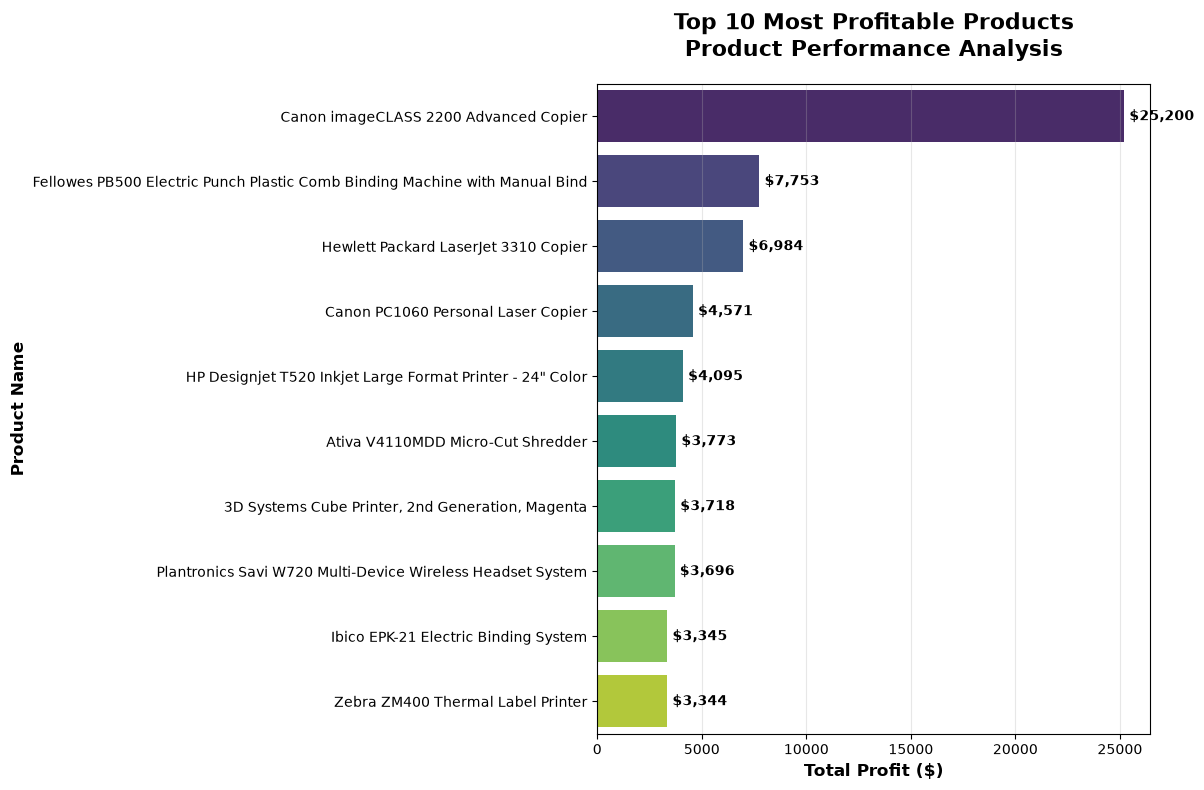

Key Insights:
• Most profitable product generates: $25,200
• Top 10 products contribute: $66,479 total profit
• Average profit per top product: $6,648


In [23]:
# Analyze top profitable products
product_profit = df.groupby('Product Name')['Profit'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 8))
ax = sns.barplot(x=product_profit.values, y=product_profit.index, 
                palette='viridis', orient='h')

# Customize the plot
plt.title('Top 10 Most Profitable Products\nProduct Performance Analysis', 
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Total Profit ($)', fontsize=12, fontweight='bold')
plt.ylabel('Product Name', fontsize=12, fontweight='bold')

# Add value annotations
for i, (product, profit) in enumerate(product_profit.items()):
    ax.text(profit + product_profit.max() * 0.01, i, f'${profit:,.0f}', 
            va='center', fontweight='bold', fontsize=10)

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("Key Insights:")
print(f"• Most profitable product generates: ${product_profit.iloc[0]:,.0f}")
print(f"• Top 10 products contribute: ${product_profit.sum():,.0f} total profit")
print(f"• Average profit per top product: ${product_profit.mean():,.0f}")

The chart highlights the top 10 most profitable products and shows that profitability is concentrated among a small number of high-performing items. The Canon imageCLASS 2200 Advanced Copier is by far the most profitable product, generating approximately $25,200 in profit, significantly outperforming all other products. The next most profitable products generate between $3,300 and $7,800, indicating a substantial gap between the top product and the rest.

Most of the products featured are technology and office equipment products, including copiers, printers, shredders, and binding machines. This suggests that technology-related products are major contributors to the company's profitability and align with earlier findings that the Technology category is a key driver of business performance.

Overall, the chart indicates that a relatively small group of high-value products contributes a disproportionate share of total profit, highlighting important opportunities for targeted marketing, inventory management, and strategic investment.

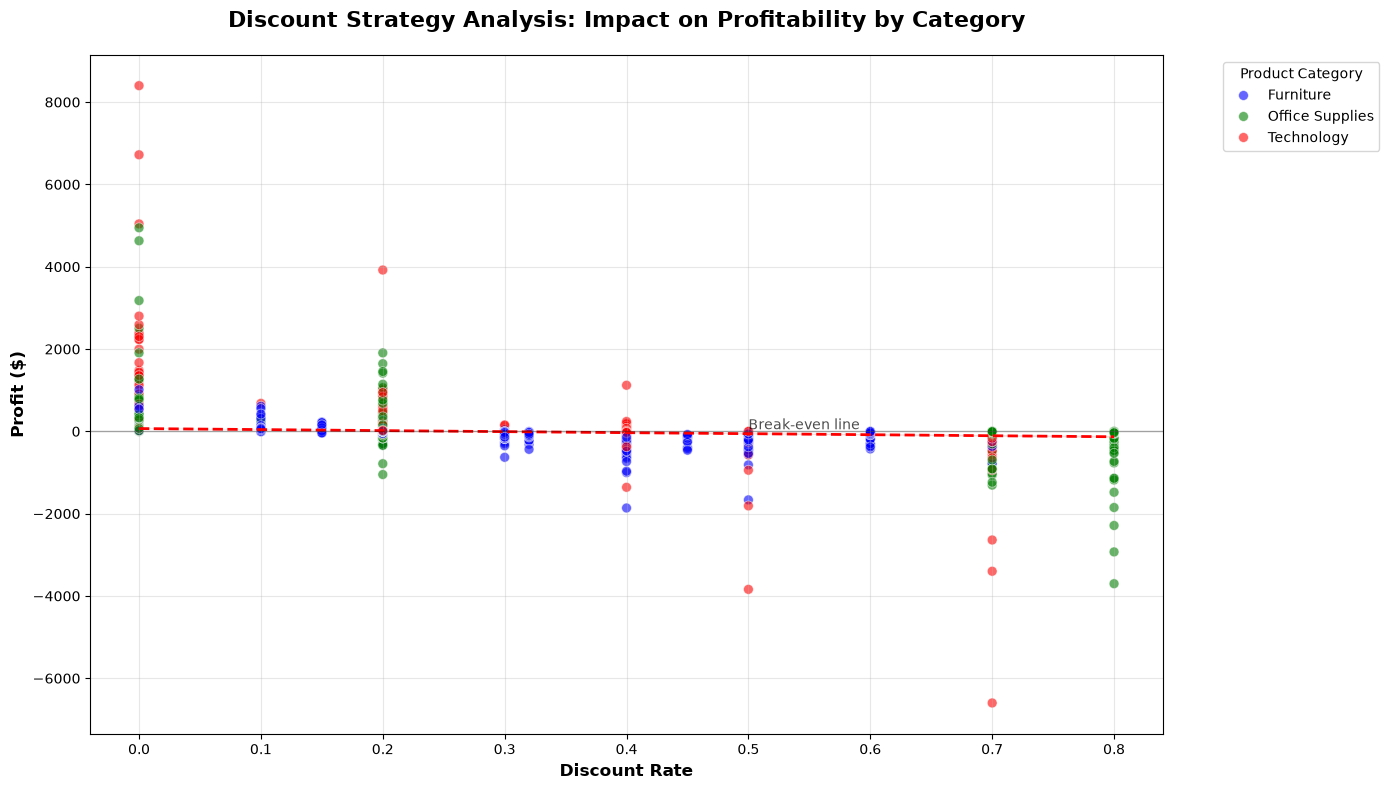

Discount Analysis Insights:
• Transactions with >20% discount: 1,393
• Average profit for high discounts: $-97.18
• Percentage of high-discount sales with losses: 96.8%

Category-specific discount impact:
• Furniture: Average profit at >20% discount = $-100.51
• Office Supplies: Average profit at >20% discount = $-69.32
• Technology: Average profit at >20% discount = $-197.42


In [20]:
# Discount vs Profit Analysis
plt.figure(figsize=(14, 8))

# Create the scatter plot with category colors
sns.scatterplot(data=df, x='Discount', y='Profit', hue='Category', palette={
        'Furniture': 'blue',
        'Office Supplies': 'green',
        'Technology': 'red'
    },

               alpha=0.6, s=50)

# Add regression line for overall trend
sns.regplot(data=df, x='Discount', y='Profit', scatter=False, 
           color='red', line_kws={'linewidth': 2, 'linestyle': '--'})

# Customize the plot
plt.title('Discount Strategy Analysis: Impact on Profitability by Category', 
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Discount Rate', fontsize=12, fontweight='bold')
plt.ylabel('Profit ($)', fontsize=12, fontweight='bold')

# Add horizontal line at profit = 0
plt.axhline(y=0, color='black', linestyle='-', alpha=0.3, linewidth=1)
plt.text(0.5, 50, 'Break-even line', fontsize=10, alpha=0.7)

plt.grid(True, alpha=0.3)
plt.legend(title='Product Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Analytical insights
print("Discount Analysis Insights:")
high_discount = df[df['Discount'] > 0.2]  # Discounts above 20%
print(f"• Transactions with >20% discount: {len(high_discount):,}")
print(f"• Average profit for high discounts: ${high_discount['Profit'].mean():.2f}")
print(f"• Percentage of high-discount sales with losses: {(high_discount['Profit'] < 0).mean()*100:.1f}%")

# Category-specific analysis
print("\nCategory-specific discount impact:")
for category in df['Category'].unique():
    cat_data = df[df['Category'] == category]
    high_disc_cat = cat_data[cat_data['Discount'] > 0.2]
    if len(high_disc_cat) > 0:
        avg_loss = high_disc_cat['Profit'].mean()
        print(f"• {category}: Average profit at >20% discount = ${avg_loss:.2f}")

Discount Strategy Analysis: Impact on Profitability

The scatterplot reveals a clear negative relationship between discount rate and profit, indicating that profitability generally declines as discounts increase. This pattern is reinforced by the downward-sloping regression line, which suggests that higher discounts are associated with lower profit margins across the dataset.

The chart shows that transactions with discounts below 20% are predominantly profitable, with several high-profit outliers observed across all product categories. However, as discounts increase beyond 30%-40%, loss-making transactions become noticeably more frequent. At discount levels of 50% and above, a substantial proportion of transactions generate negative profits, while discounts in the 70%-80% range are associated with consistently significant losses. These findings suggest that aggressive discounting can erode profitability and should be applied cautiously.

Category-Level Insights: Technology
Technology products achieve the highest profits when sold with little or no discount, including several exceptionally profitable transactions. However, this category also experiences some of the largest losses at higher discount levels, indicating that profitability is highly sensitive to aggressive discounting strategies.

Office Supplies
Office Supplies maintain moderate profitability at lower discount rates, but performance deteriorates as discounts increase. At discount levels between 70% and 80%, many transactions become loss-making, with several substantial losses evident in the data.

Furniture
Furniture products exhibit comparatively lower profit margins overall and begin to experience losses at more moderate discount levels, typically around 30%-40%. This suggests that Furniture is particularly vulnerable to discount-driven profit erosion.

Conclusion

The analysis demonstrates that while discounting may help drive sales volume, excessive discounts have a significant negative impact on profitability. Discounts exceeding 30%-40% appear to represent a tipping point where losses become increasingly common, particularly within the Furniture category. Technology products offer the greatest profit potential at low discount levels but also carry the highest risk of substantial losses when heavily discounted. Overall, the results suggest that maintaining moderate discount levels is critical to preserving profit margins across all product categories.

=== LIBRARY COMPARISON ANALYSIS ===

MATPLOTLIB STRENGTHS (from our analysis): Throughout this project, Matplotlib proved to be a highly flexible visualisation library and was particularly effective for creating interactive and customised charts.
• Fine-grained control over interactive widgets allowing seamless integration with ipywidgets for dynamic data exploration.
• Custom annotations and text positioningenabling the addition of value labels, insights, and executive-level commentary directly onto visualisations.
• Precise subplot layouts and figure sizing providing complete control over chart appearance and presentation.
• Integration with ipywidgets for dynamic updates, supporting interactive dashboards and real-time visual updates.

SEABORN STRENGTHS (from our analysis): Throughout this project, Seaborn was highly effective for creating visually appealing and statistically informative visualisations with minimal code. Its high-level interface simplified the process of exploring r

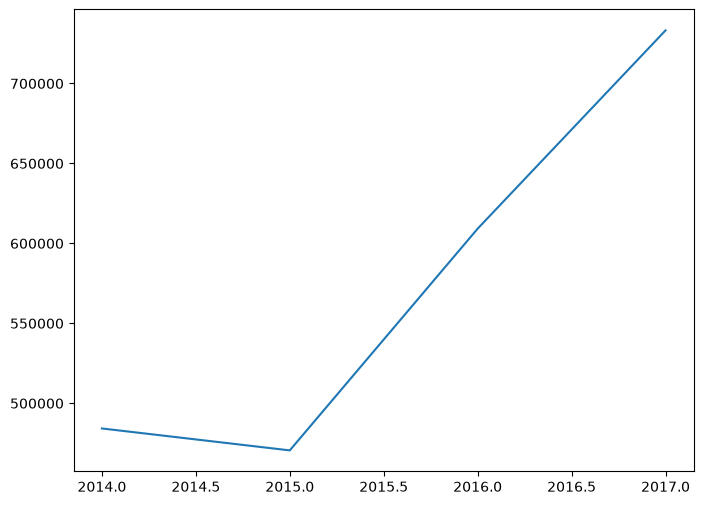

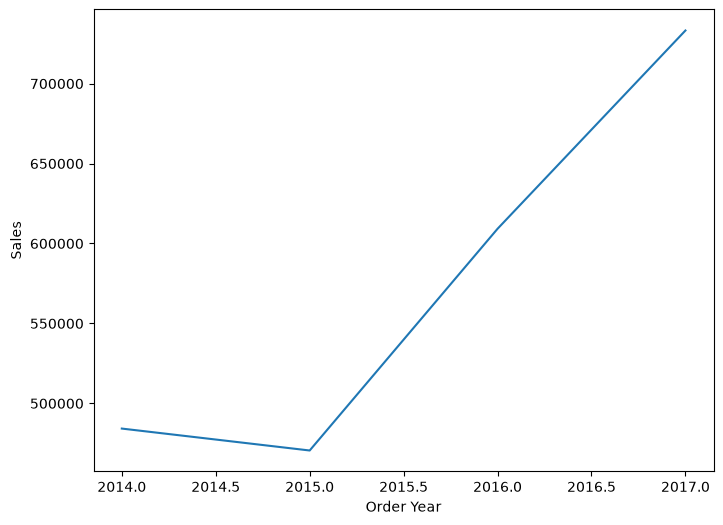

• Matplotlib basic plot: 0.3917 seconds
• Seaborn equivalent: 0.3379 seconds


In [32]:
# Code to demonstrate library comparison
print("=== LIBRARY COMPARISON ANALYSIS ===")
print()

# Matplotlib strengths demonstrated
print("MATPLOTLIB STRENGTHS (from our analysis): Throughout this project, Matplotlib proved to be a highly flexible visualisation library and was particularly effective for creating interactive and customised charts.")
print("• Fine-grained control over interactive widgets allowing seamless integration with ipywidgets for dynamic data exploration.")
print("• Custom annotations and text positioningenabling the addition of value labels, insights, and executive-level commentary directly onto visualisations.") 
print("• Precise subplot layouts and figure sizing providing complete control over chart appearance and presentation.")
print("• Integration with ipywidgets for dynamic updates, supporting interactive dashboards and real-time visual updates.")
print()

# Seaborn strengths demonstrated  
print("SEABORN STRENGTHS (from our analysis): Throughout this project, Seaborn was highly effective for creating visually appealing and statistically informative visualisations with minimal code. Its high-level interface simplified the process of exploring relationships within the data while producing professional-quality charts suitable for business reporting.")
print("• Built-in statistical visualizations (regplot), which enabled the identification of trends and relationships between variables, including the impact of discounting on profitability.")
print("• Automatic color palettes and legends, making it easy to distinguish between categories and improve chart readability without extensive customisation.")
print("• Clean, publication-ready default styling, resulting in professional visualisations that required minimal formatting.")
print("• Easy categorical data visualization, using features such as hue to automatically group and colour data by category.")
print("""
Seaborn was used to create:

• The Discount vs Profit scatter plot, revealing the relationship between discount levels and profitability.
• Category-based visualisations using colour-coded groups, allowing comparisons between Furniture, Office Supplies, and Technology.
• Statistical trend analysis through the addition of regression lines, helping identify the negative correlation between discount rates and profit.
• Presentation-quality charts that effectively communicated business insights to both technical and non-technical audiences.

These capabilities made Seaborn particularly valuable for identifying patterns, exploring category-level trends, and producing stakeholder-ready visualisations with minimal development effort.
""")
print()

print("SPEED COMPARISON:")
import time

# Time a simple matplotlib plot
start = time.time()
plt.figure(figsize=(8, 6))
plt.plot(df.groupby('Order Year')['Sales'].sum())
plt.show()
matplotlib_time = time.time() - start

# Time a seaborn plot
start = time.time()
plt.figure(figsize=(8, 6))
sns.lineplot(data=df.groupby('Order Year')['Sales'].sum().reset_index(), 
             x='Order Year', y='Sales')
plt.show()
seaborn_time = time.time() - start

print(f"• Matplotlib basic plot: {matplotlib_time:.4f} seconds")
print(f"• Seaborn equivalent: {seaborn_time:.4f} seconds")

For rapid exploratory data analysis, I would use Matplotlib because it provides greater flexibility and control over individual chart elements, making it well suited for creating custom visualisations and integrating interactive features such as ipywidgets. Its lightweight structure and direct plotting capabilities also make it effective for dynamically updating charts during data exploration and hypothesis testing.

For executive reporting and stakeholder-facing presentations, I would prefer Seaborn because it offers aesthetically pleasing, publication-quality visualisations with minimal code. Seaborn's built-in themes, colour palettes, and statistical plotting functions make it easier to communicate insights clearly and professionally. Features such as automatic grouping through hue, confidence intervals, and attractive default styling help highlight patterns and relationships in the data, making the results more accessible to non-technical audiences.

Overall, Matplotlib is the stronger choice for customisation, interactivity, and exploratory analysis, while Seaborn excels at producing visually appealing, statistically enriched visualisations for communicating findings and supporting business decision-making.

In [36]:
# Generate automated insights for executive summary
print("=== EXECUTIVE SUMMARY - KEY FINDINGS ===")
print()

# Sales performance metrics
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
profit_margin = (total_profit / total_sales) * 100
monthly_sales_all = df.groupby('Order Month-Year')['Sales'].sum()

best_month = monthly_sales_all.idxmax()
best_sales = monthly_sales_all.max()

print(
    f"• Peak sales period: {best_month} "
    f"with ${best_sales:,.0f} in revenue."
)

print(f"📊 BUSINESS PERFORMANCE:")
print(f"• Total Revenue: ${total_sales:,.0f}")
print(f"• Total Profit: ${total_profit:,.0f}")
print(f"• Overall Profit Margin: {profit_margin:.1f}%")
print()

# Geographic insights
top_state = state_sales.index[-1]
top_state_sales = state_sales.iloc[-1]
print(f"🗺️ GEOGRAPHIC PERFORMANCE:")
print(f"• Top performing state: {top_state} (${top_state_sales:,.0f})")
print(f"• Geographic concentration: Top 5 states = {(state_sales.tail(5).sum()/total_sales)*100:.1f}% of sales")
top_state_pct = (top_state_sales / total_sales) * 100

print(
    f"• {top_state} contributes "
    f"{top_state_pct:.1f}% of total company sales."
)

print()

# Product insights
top_category = df.groupby('Category')['Sales'].sum().sort_values(ascending=False).index[0]
print(f"🏆 PRODUCT PERFORMANCE:")
print(f"• Leading category: {top_category}")
print(f"• Most profitable product: {product_profit.index[0]}")
category_profit = df.groupby('Category')['Profit'].sum()

print(
    f"• Most profitable category: "
    f"{category_profit.idxmax()} "
    f"(${category_profit.max():,.0f})"
)
print(
    f"• Lowest profit category: "
    f"{category_profit.idxmin()} "
    f"(${category_profit.min():,.0f})"
)
category_sales = df.groupby('Category')['Sales'].sum()

tech_share = (
    category_sales['Technology']
    / category_sales.sum()
) * 100

print(
    f"• Technology accounts for "
    f"{tech_share:.1f}% of total sales revenue."
)
print()

# Discount insights
high_discount_loss_rate = (df[df['Discount'] > 0.2]['Profit'] < 0).mean() * 100
print(f"💰 DISCOUNT STRATEGY INSIGHTS:")
print(f"• High discount risk: {high_discount_loss_rate:.1f}% of >20% discounts result in losses")
print(f"• Recommended max discount threshold: 20% to maintain profitability")
print()
# Discount thresholds analysis
discount_thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

print("📉 DISCOUNT IMPACT ANALYSIS:")

for threshold in discount_thresholds:
    subset = df[df['Discount'] >= threshold]

    if len(subset) > 0:
        avg_profit = subset['Profit'].mean()
        loss_rate = (subset['Profit'] < 0).mean() * 100

        print(
            f"• Discounts ≥ {threshold:.0%}: "
            f"Avg Profit = ${avg_profit:.2f}, "
            f"Loss Rate = {loss_rate:.1f}%"
        )
high_discount = df[df['Discount'] > 0.3]

print()
print("🔍 ADDITIONAL BUSINESS INSIGHTS:")

if high_discount['Profit'].mean() < 0:
    print(
        f"• Discounts above 30% generate an average loss "
        f"of ${abs(high_discount['Profit'].mean()):.2f} per transaction."
    )

print("🎯 STRATEGIC INSIGHTS:")

print(
    f"• Technology is the leading category, generating "
    f"{tech_share:.1f}% of total sales."
)

print(
    f"• California remains the strongest market, contributing "
    f"{top_state_pct:.1f}% of total revenue."
)

print(
    f"• The Canon imageCLASS 2200 Advanced Copier is the most "
    f"profitable product in the portfolio."
)

if high_discount['Profit'].mean() < 0:
    print(
        f"• Discounts above 30% result in average losses of "
        f"${abs(high_discount['Profit'].mean()):.2f} per transaction."
    )

print(
    "• Year-end periods consistently generate the highest sales "
    "volumes, indicating strong seasonal demand."
)

=== EXECUTIVE SUMMARY - KEY FINDINGS ===

• Peak sales period: 2017-11 with $118,448 in revenue.
📊 BUSINESS PERFORMANCE:
• Total Revenue: $2,297,201
• Total Profit: $286,397
• Overall Profit Margin: 12.5%

🗺️ GEOGRAPHIC PERFORMANCE:
• Top performing state: California ($457,688)
• Geographic concentration: Top 5 states = 52.0% of sales
• California contributes 19.9% of total company sales.

🏆 PRODUCT PERFORMANCE:
• Leading category: Technology
• Most profitable product: Canon imageCLASS 2200 Advanced Copier
• Most profitable category: Technology ($145,455)
• Lowest profit category: Furniture ($18,451)
• Technology accounts for 36.4% of total sales revenue.

💰 DISCOUNT STRATEGY INSIGHTS:
• High discount risk: 96.8% of >20% discounts result in losses
• Recommended max discount threshold: 20% to maintain profitability

📉 DISCOUNT IMPACT ANALYSIS:
• Discounts ≥ 10%: Avg Profit = $-6.66, Loss Rate = 36.0%
• Discounts ≥ 20%: Avg Profit = $-8.92, Loss Rate = 36.6%
• Discounts ≥ 30%: Avg Profit